# 02 — Variables, binning WOE e IV

**Objetivo.** Construir las variables candidatas, agruparlas en bins con weight of evidence (WOE),
medir cuánta información aporta cada una (IV) y decidir cuáles pasan al modelo de la fase
siguiente. Las decisiones quedan registradas en `docs/DECISIONS.md` (ADR-009 y ADR-011).

**Todo se calcula solo con la parte de entrenamiento** (24,000 filas). El conjunto de test no se
carga en este notebook.

Convenciones:

- WOE de un bin = ln(proporción de no-defaults del bin / proporción de defaults del bin). Un bin
  más riesgoso que el promedio tiene WOE negativo.
- IV = suma, sobre los bins, de (proporción de no-defaults − proporción de defaults) × WOE.
- Bandas habituales del IV: <0.02 inútil, 0.02–0.1 débil, 0.1–0.3 medio, 0.3–0.5 fuerte,
  >0.5 sospechoso (revisar fuga de información).

Todos los cálculos están en `creditrisk.features`. Este notebook llama a `woe_iv_report`, que
produce todas las cifras de una sola vez, y las guarda en `reports/metrics/woe_iv.json`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from creditrisk import plotting
from creditrisk.config import load_config
from creditrisk.data.schema import MONTH_LABELS
from creditrisk.data.split import load_train
from creditrisk.features.engineering import FEATURE_SPECS, build_features
from creditrisk.features.selection import EXCLUDED_FROM_CHAMPION, woe_iv_report
from creditrisk.reporting import save_metrics

plotting.apply_style()
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

BANDS = {
    "useless": "inútil",
    "weak": "débil",
    "medium": "medio",
    "strong": "fuerte",
    "suspicious": "sospechoso",
}
TRENDS = {"ascending": "sube", "descending": "baja", None: "sin restricción"}
DTYPES = {"numerical": "numérica", "categorical": "categórica"}

## 1. Datos de entrenamiento y variables candidatas

Las variables se construyen fila por fila a partir de las columnas de cada cliente, sin ajustar
nada a los datos (`build_features`). Cada una responde a una idea de negocio:

| Grupo | Variables | Idea |
|---|---|---|
| Límite | `LIMIT_BAL` | El banco da límites más altos a clientes en quienes ya confía. |
| Demográficas | `AGE`, `EDUCATION` | La edad se asocia con la etapa de vida y la estabilidad de ingresos; la educación, con la capacidad de generar ingresos. Por ser atributos demográficos, ADR-002 exige justificar su inclusión. |
| Utilización | `UTIL_1`…`UTIL_6`, `UTIL_MEAN`, `UTIL_MAX`, `UTIL_TREND` | Factura / límite. Una línea más usada indica más tensión financiera. La factura negativa cuenta como cero. `UTIL_TREND` es la utilización de septiembre menos la de abril. |
| Ratio de pago | `PAY_RATIO_1`…`PAY_RATIO_5`, `PAY_RATIO_MEAN` | Pago del mes / estado de cuenta que cancela (ADR-009). Sin nada que pagar, el valor queda vacío y va a un bin propio. |
| Historial de mora | `N_DELAY_MONTHS`, `MAX_DELAY`, `MONTHS_SINCE_DELAY` | Atrasos de agosto a abril, los meses con codificación consistente (ADR-008). |
| Estado de pago | `STATUS_SEP`, `STATUS_AUG` | Estado de septiembre y de agosto como categorías; los atrasos de 3 o más meses se agrupan en "3+". |
| Inactividad | `INACTIVE` | Todas las facturas y pagos en cero. |

In [2]:
train = load_train()
features = build_features(train)
print(f"Filas de entrenamiento: {len(train):,}")
print(f"Variables candidatas:   {features.shape[1]}")

# The whole Phase 4 analysis: binning, IV, stability across folds and preselection.
report = woe_iv_report(train)

Filas de entrenamiento: 24,000
Variables candidatas:   24


## 2. Reglas del binning

Cada bin debe tener al menos el 5% de las filas, salvo el bin de valores vacíos, que no tiene mínimo.
Para las variables numéricas se declaró, antes de mirar los datos y según la lógica de negocio, en
qué dirección debe moverse la tasa de default; el binning respeta esa dirección. La edad va sin
restricción, porque el riesgo puede ser mayor en ambos extremos; el precio de esa libertad es que
el binning encuentra muchos bins pequeños.

In [3]:
settings = report["settings"]
rules = pd.DataFrame(
    {
        "tipo": {k: DTYPES[v["dtype"]] for k, v in FEATURE_SPECS.items()},
        "la tasa de default ... al crecer la variable": {
            k: TRENDS[v] for k, v in settings["monotonic_trend"].items()
        },
    }
)
rules.index.name = "variable"
print(f"Tamaño mínimo de bin: {settings['min_bin_size']:.0%} de las filas (salvo el bin de vacíos)")
display(rules)

Tamaño mínimo de bin: 5% de las filas (salvo el bin de vacíos)


,tipo,la tasa de default ... al crecer la variable
variable,,
LIMIT_BAL,numérica,baja
AGE,numérica,sin restricción
EDUCATION,categórica,sin restricción
UTIL_1,numérica,sube
UTIL_2,numérica,sube
UTIL_3,numérica,sube
UTIL_4,numérica,sube
UTIL_5,numérica,sube
UTIL_6,numérica,sube


## 3. Information value de cada variable

La columna `IV (optbinning)` es el IV que calcula la librería que encuentra los cortes; la columna
`IV` es nuestro propio cálculo sobre los mismos bins. Deben coincidir: es la verificación cruzada
que pide la fase.

In [4]:
iv = pd.DataFrame(report["iv_table"]).set_index("feature").sort_values("iv", ascending=False)
iv_view = pd.DataFrame(
    {
        "IV": iv["iv"].round(3),
        "IV (optbinning)": iv["optbinning_iv"].round(3),
        "banda": iv["band"].map(BANDS),
        "bins": iv["n_bins"],
        "bin de vacíos": iv["has_missing_bin"].map({True: "sí", False: "no"}),
    }
)
iv_view.index.name = "variable"
display(iv_view)
largest_gap = (iv["iv"] - iv["optbinning_iv"]).abs().max()
print(f"Máxima diferencia entre los dos cálculos de IV: {largest_gap:.1e}")

,IV,IV (optbinning),banda,bins,bin de vacíos
variable,,,,,
STATUS_SEP,0.873,0.873,sospechoso,5,no
N_DELAY_MONTHS,0.641,0.641,sospechoso,4,no
MONTHS_SINCE_DELAY,0.630,0.630,sospechoso,2,sí
STATUS_AUG,0.550,0.550,sospechoso,4,no
MAX_DELAY,0.531,0.531,sospechoso,2,no
PAY_RATIO_1,0.266,0.266,medio,5,sí
PAY_RATIO_2,0.218,0.218,medio,6,sí
PAY_RATIO_MEAN,0.210,0.210,medio,7,sí
PAY_RATIO_3,0.193,0.193,medio,4,sí


Máxima diferencia entre los dos cálculos de IV: 1.1e-16


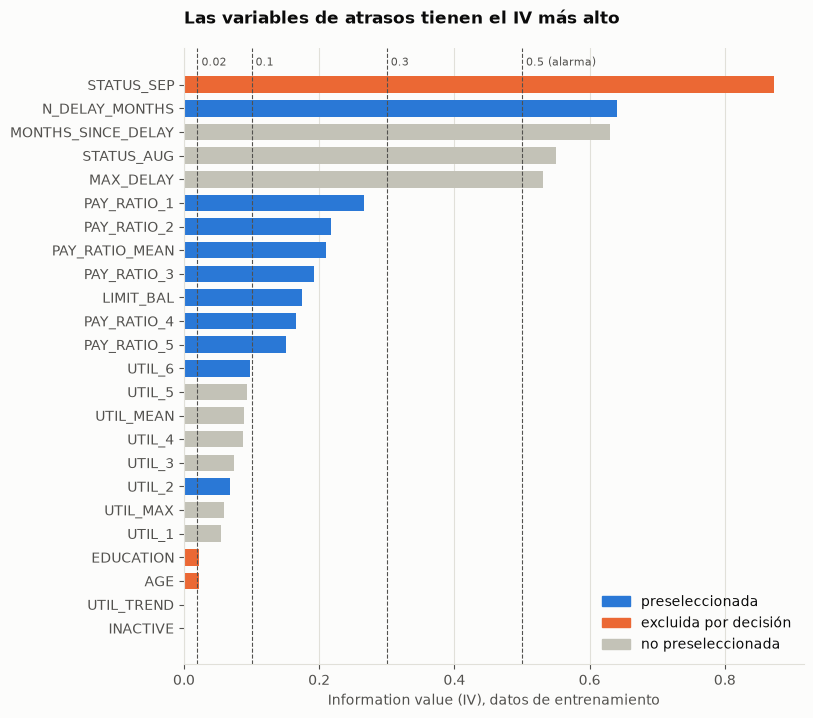

In [5]:
shortlist = set(report["shortlist"])
excluded = set(EXCLUDED_FROM_CHAMPION)
ordered = iv.sort_values("iv")


def group(name):
    if name in shortlist:
        return "preseleccionada"
    if name in excluded:
        return "excluida por decisión"
    return "no preseleccionada"


colours = {
    "preseleccionada": plotting.BLUE,
    "excluida por decisión": plotting.ORANGE,
    "no preseleccionada": "#c3c2b7",
}
fig, ax = plt.subplots(figsize=(8, 8))
groups = ordered.index.map(group)
ax.barh(ordered.index, ordered["iv"], color=[colours[g] for g in groups], height=0.7)
band_lines = {0.02: "0.02", 0.1: "0.1", 0.3: "0.3", 0.5: "0.5 (alarma)"}
for value, label in band_lines.items():
    ax.axvline(value, color=plotting.MUTED, linewidth=0.8, linestyle="--")
    ax.text(value, len(ordered) - 0.3, f" {label}", color=plotting.MUTED, fontsize=8, va="bottom")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in colours.values()]
ax.legend(handles, colours.keys(), loc="lower right")
ax.set_xlabel("Information value (IV), datos de entrenamiento")
ax.grid(axis="y", visible=False)
ax.set_title("Las variables de atrasos tienen el IV más alto", pad=18)
plotting.save_figure(fig, "woe_iv_by_feature")
plt.show()

## 4. Variables por encima del umbral de alarma (IV > 0.5)

Cinco variables superan 0.5: el estado de septiembre, el estado de agosto y las tres variables de
historial de mora. Un IV tan alto puede indicar fuga de información, así que cada una se revisa.

### El estado de septiembre (`PAY_1`)

ADR-009 dejó pendiente esta verificación: no se puede demostrar que `PAY_1` se registró antes del
resultado de octubre. El gráfico muestra el IV del estado de pago de cada mes, con la misma regla de
agrupación.

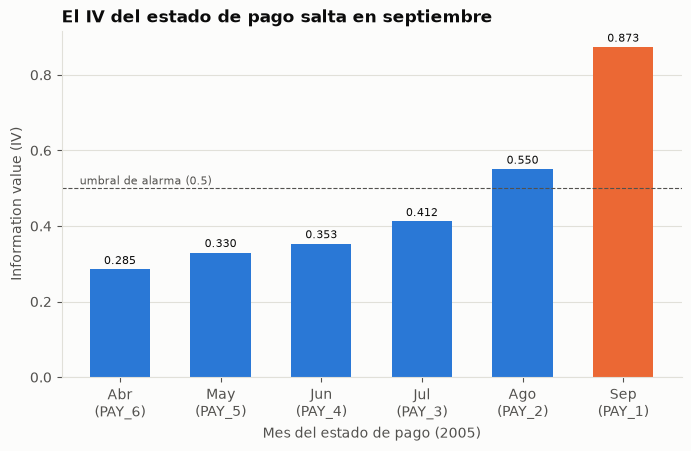

In [6]:
by_month = pd.Series(report["pay_1_check"]["status_iv_by_month"]).sort_index(ascending=False)
labels = [f"{MONTH_LABELS[int(k)]}\n(PAY_{k})" for k in by_month.index]

fig, ax = plt.subplots(figsize=(8, 4.5))
colours = [plotting.ORANGE if int(k) == 1 else plotting.BLUE for k in by_month.index]
bars = ax.bar(labels, by_month.to_numpy(), color=colours, width=0.6)
ax.bar_label(bars, labels=[f"{v:.3f}" for v in by_month], padding=2, fontsize=8)
ax.axhline(0.5, color=plotting.MUTED, linewidth=0.8, linestyle="--")
ax.text(-0.4, 0.51, "umbral de alarma (0.5)", color=plotting.MUTED, fontsize=8)
ax.set_xlabel("Mes del estado de pago (2005)")
ax.set_ylabel("Information value (IV)")
ax.grid(axis="x", visible=False)
ax.set_title("El IV del estado de pago salta en septiembre")
plotting.save_figure(fig, "woe_status_iv_by_month")
plt.show()

El IV crece con la cercanía al resultado, lo que es esperable, pero el salto de agosto (0.550) a
septiembre (0.873) es mucho mayor que los anteriores. Puede ser solo recencia o puede ser
información del mes del resultado; el archivo no permite distinguirlo. El notebook 01 mostró además
que el código de septiembre no es comparable con el de los meses anteriores (parece registrado con
otro criterio), así que su IV no se puede leer en la misma escala que el de los otros meses.

**Decisión (ADR-009, actualizado).** El modelo campeón se construye **sin** `STATUS_SEP`. El modelo
con `STATUS_SEP` se ajusta en la fase siguiente solo como sensibilidad, para mostrar cuánto
ganaría la predicción si el dato fuera legítimo. Los montos de septiembre (`BILL_AMT1`, `PAY_AMT1`)
sí se usan: en el notebook 01 quedó establecido qué estado de cuenta paga cada pago, y que se
conocieran antes de octubre sigue siendo el **SUPUESTO** de ADR-009.

### El historial de agosto a abril

`N_DELAY_MONTHS`, `MONTHS_SINCE_DELAY`, `MAX_DELAY` y `STATUS_AUG` vienen de meses anteriores a
septiembre y con codificación consistente, así que no deberían contener información de octubre,
bajo el **SUPUESTO** de ADR-009 sobre las fechas de registro. Dos datos lo apoyan: el IV mensual
crece de forma gradual de abril a agosto, y en los 15 folds el IV fuera del fold de `STATUS_AUG`
(entre 0.47 y 0.62) no se cruza con el de `STATUS_SEP` (entre 0.78 y 0.97; tabla de la sección 6).
Que el historial de atrasos sea el predictor más fuerte es lo esperable en un scorecard de
comportamiento. **Decisión (ADR-011):** se conservan como candidatas.

## 5. Cómo se ve el riesgo dentro de los bins

Tasa de default por bin para cuatro variables, en los datos de entrenamiento. La línea discontinua
es la tasa promedio. Que la tasa suba o baje de un bin al siguiente **no es un hallazgo**: el
binning impone esa dirección. Lo que muestra el gráfico es cuánto se separan los bins. La prueba de
que ese orden se sostiene en filas no vistas está en la sección 6. El bin de "nada que pagar" de
los ratios de pago queda aparte, en gris, porque no forma parte del orden.

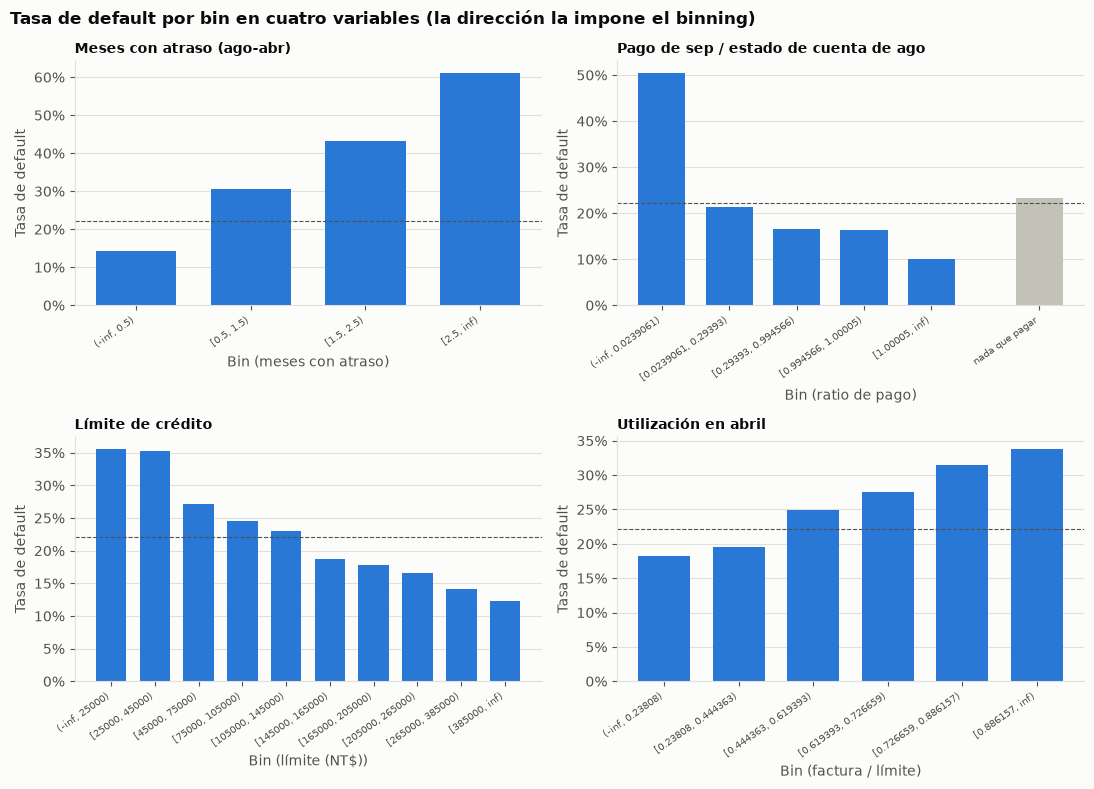

In [7]:
bins = report["bins"]
overall = train["DEFAULT"].mean()
panels = {
    "N_DELAY_MONTHS": ("Meses con atraso (ago-abr)", "meses con atraso"),
    "PAY_RATIO_1": ("Pago de sep / estado de cuenta de ago", "ratio de pago"),
    "LIMIT_BAL": ("Límite de crédito", "límite (NT$)"),
    "UTIL_6": ("Utilización en abril", "factura / límite"),
}
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, (name, (title, xlabel)) in zip(axes.ravel(), panels.items(), strict=True):
    table = pd.DataFrame(bins[name])
    is_missing = table["bin"] == "missing"
    names = table["bin"].replace({"missing": "nada que pagar"})
    colours = ["#c3c2b7" if m else plotting.BLUE for m in is_missing]
    positions = [i + (0.6 if m else 0) for i, m in enumerate(is_missing)]
    ax.bar(positions, table["event_rate"], color=colours, width=0.7)
    ax.axhline(overall, color=plotting.MUTED, linewidth=0.8, linestyle="--")
    ax.set_xticks(positions, names, rotation=35, ha="right", fontsize=7)
    ax.yaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
    ax.set_ylabel("Tasa de default")
    ax.set_xlabel(f"Bin ({xlabel})")
    ax.grid(axis="x", visible=False)
    ax.set_title(title, fontsize=10)
fig.suptitle(
    "Tasa de default por bin en cuatro variables (la dirección la impone el binning)",
    x=0.01,
    ha="left",
    fontweight="bold",
)
fig.tight_layout()
plotting.save_figure(fig, "woe_event_rate_by_bin")
plt.show()

Dos variables de historial quedaron con solo dos bins: `MAX_DELAY` separa "algún atraso" de
"ninguno" y pierde la severidad del atraso, y `MONTHS_SINCE_DELAY` hace algo parecido. Ambas quedan
fuera de la preselección por su correlación con `N_DELAY_MONTHS` (sección 7).

## 6. Estabilidad entre folds

El binning se vuelve a ajustar en cada uno de los 15 folds de validación cruzada (con 4/5 de
train) y se evalúa en el 1/5 que no vio:

- **IV fuera del fold**: el IV de esos mismos bins en las filas de validación.
- **IV por azar**: con muestras chicas, el IV sale positivo aunque la variable no sirva, y más
  cuantos más bins tenga. Para medirlo, en cada fold se baraja el target de validación 100 veces,
  manteniendo los bins. La columna "folds sobre el azar" cuenta los folds en que el IV fuera del
  fold supera el percentil 95 de esos IV barajados.
- **Orden de riesgo**: correlación de rangos entre el WOE de los bins en el ajuste y en validación
  (1 = el orden se mantiene). Es una medida gruesa: con muchos bins de riesgo parecido varía por
  ruido, y con solo dos bins vale siempre 1 o −1.

In [8]:
stability = pd.DataFrame(report["fold_stability"]).set_index("feature")
bin_range = stability["n_bins_min"].astype(str) + "-" + stability["n_bins_max"].astype(str)
stability_view = pd.DataFrame(
    {
        "IV ajuste": stability["iv_fit_mean"].round(3),
        "IV fuera del fold": stability["iv_valid_mean"].round(3),
        "IV fuera (mín)": stability["iv_valid_min"].round(3),
        "IV fuera (máx)": stability["iv_valid_max"].round(3),
        "IV por azar": stability["iv_null_mean"].round(3),
        "folds sobre el azar": stability["n_folds_iv_valid_above_null_p95"],
        "folds con IV ≥ 0.02": stability["n_folds_iv_valid_at_least_min"],
        "orden de riesgo (media)": stability["woe_rank_corr_mean"].round(2),
        "orden de riesgo (mín)": stability["woe_rank_corr_min"].round(2),
        "bins": bin_range,
    }
)
stability_view.index.name = "variable"
display(stability_view.sort_values("IV ajuste", ascending=False))

,IV ajuste,IV fuera del fold,IV fuera (mín),IV fuera (máx),IV por azar,folds sobre el azar,folds con IV ≥ 0.02,orden de riesgo (media),orden de riesgo (mín),bins
variable,,,,,,,,,,
STATUS_SEP,0.874,0.878,0.781,0.966,0.005,15,15,0.95,0.90,5-5
N_DELAY_MONTHS,0.642,0.640,0.560,0.730,0.004,15,15,1.00,1.00,4-4
MONTHS_SINCE_DELAY,0.630,0.631,0.551,0.680,0.002,15,15,1.00,1.00,2-2
STATUS_AUG,0.551,0.554,0.473,0.622,0.004,15,15,0.73,0.40,4-4
MAX_DELAY,0.531,0.531,0.468,0.588,0.001,15,15,1.00,1.00,2-2
PAY_RATIO_1,0.267,0.267,0.205,0.321,0.006,15,15,0.96,0.86,4-6
PAY_RATIO_2,0.219,0.216,0.170,0.257,0.007,15,15,0.95,0.83,5-6
PAY_RATIO_MEAN,0.212,0.210,0.161,0.246,0.009,15,15,0.96,0.87,7-8
PAY_RATIO_3,0.193,0.194,0.157,0.236,0.006,15,15,0.90,0.68,4-6


### `AGE` y `EDUCATION`

ADR-002 pide decidir aquí si estas variables entran al modelo, con su IV a la vista. Las dos tienen
un IV de entrenamiento de 0.022, en el límite inferior de lo útil.

- **`AGE`**: su IV fuera del fold (0.030 de media) es en buena parte azar: barajando el target, sus
  14 bins dan 0.015 de media. Solo supera al azar en 10 de 15 folds, y el orden de riesgo de sus
  bins no se sostiene (correlación de rangos media 0.66 y mínima 0.27).
- **`EDUCATION`**: con solo 3 bins, su IV supera al azar en los 15 folds, así que tiene una señal
  real, aunque débil; llega a un IV de 0.02 fuera del fold en 10 de 15 folds porque está justo en
  ese umbral.

**Decisión (ADR-011).** Ninguna de las dos entra al modelo: `AGE` porque su señal no se distingue
bien del azar, y `EDUCATION` porque una señal tan débil no alcanza para justificar un atributo
demográfico, como exige ADR-002. Ambas se incluyen en la auditoría de equidad de la fase 12.

Para que quede claro: el criterio de estabilidad se precisó al ver los primeros resultados de
train, y la línea de azar se agregó después de la decisión, al revisar la fase. La decisión la tomó
el responsable del proyecto; para `EDUCATION`, el motivo se corrigió con la línea de azar a la vista.

`STATUS_AUG` tiene también un orden de riesgo poco estable (media 0.73, mínima 0.40), porque tres
de sus categorías tienen un riesgo muy parecido; supera al azar en los 15 folds y, de todos modos,
queda fuera por su correlación con `N_DELAY_MONTHS`. Además, el binning unió el código 1 (muy pocos
casos en agosto) con el −2, que no tiene relación de negocio; no afecta a nada porque la variable no
se usa, pero habría que corregirlo antes de reutilizarla.

`INACTIVE` tiene un solo bin: las cuentas inactivas son menos del 5% de train, el tamaño mínimo de
un bin, así que la variable no aporta información. Esas cuentas quedan incluidas en los bins de
"nada que pagar" de los ratios de pago, junto con otras cuentas.

In [9]:
inactive = report["n_train_inactive"]
print(f"Cuentas inactivas en train: {inactive:,} ({inactive / report['n_train_rows']:.1%})")

Cuentas inactivas en train: 646 (2.7%)


## 7. Preselección

Entre las candidatas que siguen en juego, se recorre la lista de mayor a menor IV y se conserva cada
variable salvo que su IV sea menor que 0.02 o que su WOE tenga una correlación mayor que 0.7 con una
variable ya conservada. Los umbrales se fijaron antes de calcular nada (ADR-011). Esta lista es
**descriptiva**: en la fase siguiente, el binning, la preselección y la selección se repiten dentro
de cada fold de validación cruzada.

In [10]:
REASONS = {"kept": "preseleccionada", "IV below 0.02": "IV menor que 0.02"}
preselection = pd.DataFrame(report["preselection"]).set_index("feature")
preselection_view = pd.DataFrame(
    {
        "IV": preselection["iv"].round(3),
        "resultado": preselection["reason"].map(
            lambda r: REASONS.get(r, r.replace("correlated with", "correlacionada con"))
        ),
    }
)
preselection_view.index.name = "variable"
display(preselection_view)

pairs = pd.DataFrame(report["correlated_pairs_all_candidates"])
with_delay = pairs[
    (pairs["feature_1"] == "N_DELAY_MONTHS") | (pairs["feature_2"] == "N_DELAY_MONTHS")
]
print("Correlación del WOE con N_DELAY_MONTHS:")
display(
    with_delay.round(3).rename(
        columns={"feature_1": "variable 1", "feature_2": "variable 2", "correlation": "correlación"}
    )
)

vif = pd.Series(report["vif_shortlist"], name="VIF").round(2)
vif.index.name = "variable"
print(f"Variables preseleccionadas: {len(report['shortlist'])}")
print(f"VIF máximo entre ellas: {vif.max():.2f} (umbral de alerta: {settings['vif_flag']:g})")
display(vif.to_frame())

,IV,resultado
variable,,
N_DELAY_MONTHS,0.641,preseleccionada
MONTHS_SINCE_DELAY,0.630,correlacionada con N_DELAY_MONTHS
STATUS_AUG,0.550,correlacionada con N_DELAY_MONTHS
MAX_DELAY,0.531,correlacionada con N_DELAY_MONTHS
PAY_RATIO_1,0.266,preseleccionada
PAY_RATIO_2,0.218,preseleccionada
PAY_RATIO_MEAN,0.210,preseleccionada
PAY_RATIO_3,0.193,preseleccionada
LIMIT_BAL,0.175,preseleccionada


Correlación del WOE con N_DELAY_MONTHS:


,variable 1,variable 2,correlación
3,N_DELAY_MONTHS,MAX_DELAY,0.920
5,N_DELAY_MONTHS,MONTHS_SINCE_DELAY,0.915
24,N_DELAY_MONTHS,STATUS_AUG,0.763


Variables preseleccionadas: 10
VIF máximo entre ellas: 2.55 (umbral de alerta: 5)


,VIF
variable,
N_DELAY_MONTHS,1.79
PAY_RATIO_1,1.61
PAY_RATIO_2,1.62
PAY_RATIO_MEAN,2.55
PAY_RATIO_3,1.47
LIMIT_BAL,1.32
PAY_RATIO_4,1.38
PAY_RATIO_5,1.46
UTIL_6,2.06


Quedan diez variables: una de historial de mora (`N_DELAY_MONTHS`, que deja fuera a
`MONTHS_SINCE_DELAY`, `MAX_DELAY` y `STATUS_AUG` por su alta correlación con ella, mostrada arriba),
los cinco ratios de pago y su promedio, el límite de crédito y dos de utilización. Ninguna tiene un
VIF por encima del umbral de alerta.

El modelo de sensibilidad de ADR-009 se construye en la fase siguiente con las mismas candidatas más
`STATUS_SEP`, y la preselección se repite dentro de cada fold.

## 8. Limitaciones

- **IV descriptivo.** El IV y la preselección se calcularon una vez con todo train. La medición
  honesta del modelo exige repetir binning y selección dentro de cada fold, cosa que hace la fase
  siguiente.
- **Los mismos folds ya se usaron.** Las decisiones sobre `AGE` y `EDUCATION` se tomaron con los 15
  folds que la fase siguiente usará para medir el modelo; como solo quitaron dos variables con IV
  cercano a 0.02, el optimismo posible es mínimo, pero no es cero.
- **Fechas de registro.** Que las columnas usadas se conocieran antes de octubre es un SUPUESTO
  (ADR-009). `LIMIT_BAL` no tiene fecha y un banco puede ajustarlo según el comportamiento.
- **Gemelos dentro de train.** 140 filas de train tienen un gemelo en las variables candidatas
  (`reports/metrics/split.json`) y pueden caer en folds distintos, lo que favorece un poco la
  estabilidad medida.
- **Medidas de estabilidad gruesas.** La correlación de rangos con pocos bins dice poco, y el
  conteo de folds con IV ≥ 0.02 es poco informativo para variables con muchos bins; por eso se
  agregó la línea de azar.
- **Tendencias.** La única variable de tendencia es la diferencia de utilización entre septiembre y
  abril, que resultó inútil (IV menor que 0.02). No se probaron tendencias del ratio de pago ni de
  la mora.
- **Un solo período.** Todo viene de abril a septiembre de 2005; nada de esto mide estabilidad en el
  tiempo.

## 9. Guardado de resultados

Todas las cifras de este notebook, de ADR-009 y de ADR-011 salen de este archivo.

In [11]:
# load_train() already checked the raw file against this hash.
data_sha256 = load_config("project")["data"]["raw_sha256"]
path = save_metrics("woe_iv", report, data_sha256)
print(f"Guardado en {path.relative_to(path.parents[2]).as_posix()}")

Guardado en reports/metrics/woe_iv.json


## Resumen de decisiones

| Tema | Decisión | Registrada en |
|---|---|---|
| Estado de septiembre (`STATUS_SEP`, IV 0.873) | Fuera del modelo campeón; solo en el modelo de sensibilidad | ADR-009 |
| Historial de agosto a abril (IV > 0.5) | Se conserva: viene de meses anteriores al resultado (SUPUESTO de ADR-009) | ADR-011 |
| `AGE` | Fuera del modelo: su señal no se distingue bien del azar; sí en la auditoría de equidad | ADR-011 |
| `EDUCATION` | Fuera del modelo: señal real pero demasiado débil para justificar un atributo demográfico; sí en la auditoría de equidad | ADR-011 |
| Reglas de binning | Bin mínimo del 5% (salvo vacíos), dirección declarada por lógica de negocio, vacíos en bin propio | ADR-011 |
| Preselección | IV ≥ 0.02 y correlación de WOE ≤ 0.7; diez variables, como referencia para la fase siguiente | ADR-011 |